### LIBRARIES

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

### DATA

In [3]:
data = pd.read_csv("global_cancer_patients_2015_2024.csv")
data   #print(data)

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,PT0049995,80,Male,Pakistan,2023,2.3,7.5,2.8,3.8,2.9,Leukemia,Stage 0,71463.70,1.0,3.63
49996,PT0049996,40,Female,USA,2018,6.4,3.5,2.9,9.0,9.8,Colon,Stage I,49619.66,0.4,6.03
49997,PT0049997,74,Male,Pakistan,2015,6.2,1.6,8.7,4.7,4.0,Breast,Stage 0,5338.25,2.7,6.02
49998,PT0049998,21,Male,Brazil,2018,4.0,6.5,7.6,8.6,8.1,Liver,Stage IV,45100.47,7.5,6.54


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             50000 non-null  str    
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  str    
 3   Country_Region         50000 non-null  str    
 4   Year                   50000 non-null  int64  
 5   Genetic_Risk           50000 non-null  float64
 6   Air_Pollution          50000 non-null  float64
 7   Alcohol_Use            50000 non-null  float64
 8   Smoking                50000 non-null  float64
 9   Obesity_Level          50000 non-null  float64
 10  Cancer_Type            50000 non-null  str    
 11  Cancer_Stage           50000 non-null  str    
 12  Treatment_Cost_USD     50000 non-null  float64
 13  Survival_Years         50000 non-null  float64
 14  Target_Severity_Score  50000 non-null  float64
dtypes: float64(8)

In [4]:
data.duplicated().sum()     #int(data.duplicated().sum())

np.int64(0)

### DESCRIPTIVE ANALYSIS

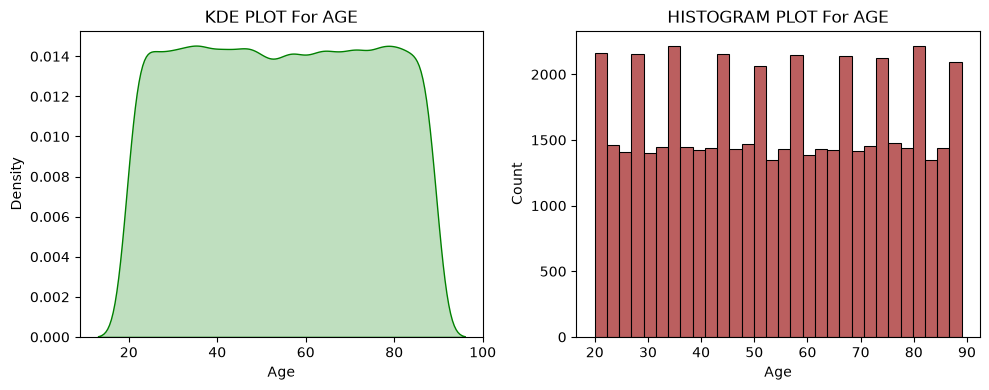

In [6]:
# PLOTTING For 'AGE' COLUMN
plt.figure(figsize= (10, 4))

plt.subplot(1, 2, 1)
sns.kdeplot(data["Age"], fill= True, color= "green")
plt.title("KDE PLOT For AGE")

plt.subplot(1, 2, 2)
sns.histplot(data["Age"], bins= 30, kde= False, color= "brown")
plt.title("HISTOGRAM PLOT For AGE")

plt.tight_layout()
plt.show()

In [7]:
data["Age"].describe()

count    50000.000000
mean        54.421540
std         20.224451
min         20.000000
25%         37.000000
50%         54.000000
75%         72.000000
max         89.000000
Name: Age, dtype: float64

##### INFERENCE

###### RANGE :  20 to 89 YEAR's
###### MEAN AGE :  54.42
###### STANDARD DEVIATION :  20.22
###### INTERQUARTILE RANGE (IQR) :  31(Q1) to 72(Q3)
###### This SUGGEST a BROAD REPRESNTATION Of BOTH YOUNG & ELDERLY PATIENT's In The DATASET, Which SUPPORT's AGE-Based COMPARATIVE ANALYSIS

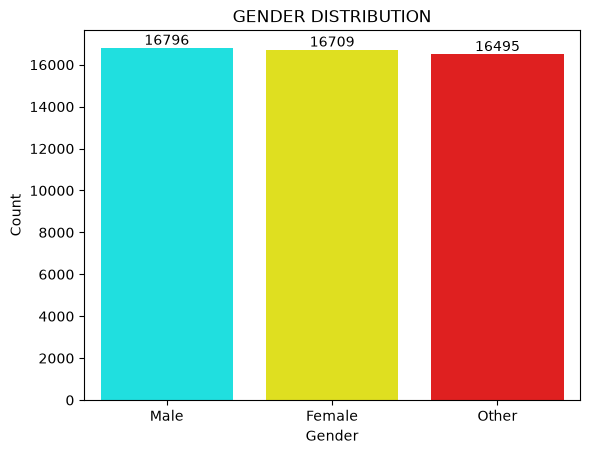

In [8]:
# PLOTTING For 'GENDER' COLUMN
data["Gender"].value_counts()

sns.barplot(x= data["Gender"].value_counts().index,
            y= data["Gender"].value_counts().values,
            palette= ["cyan", "yellow", "red"])

for i, v in enumerate(data["Gender"].value_counts()):           #VALUE SHOW VALUE (X Axis, Y Axis & Intersection Point)
    plt.text(i, v, str(v), ha= "center", va= "bottom")          #ha= HORIZONTAL, va= VERTICAL

plt.title("GENDER DISTRIBUTION")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

##### INFERENCE

###### The DATASET Contains THREE GENDER CATEGORIES (Male, Female & Other) With The MOST COMMON Being MALE (16,796 Records)
###### GENDER DISTRIBUTION Is SUFFICIENT For EVALUATING GENDER-SPECIFIC SURVIVAL TREND's and SEVERITY OUTCOME's

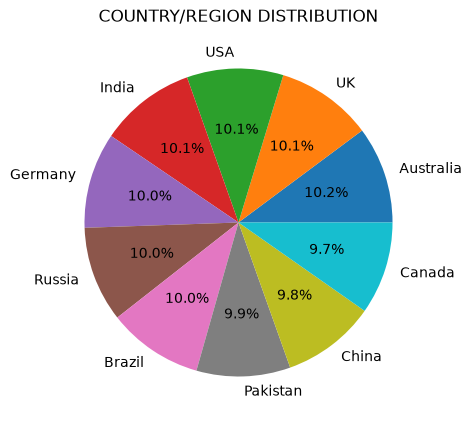

In [9]:
# PLOTTING For 'COUNTRIES' COLUMN
country_count = data["Country_Region"].value_counts()

plt.figure(figsize= (5, 5))
plt.pie(x= country_count.values,
        labels= country_count.index,
        autopct= "%1.1f%%")            #SHOW VALUEs

plt.title("COUNTRY/REGION DISTRIBUTION")
plt.show()

In [10]:
country_count

Country_Region
Australia    5092
UK           5060
USA          5060
India        5040
Germany      5024
Russia       5017
Brazil       5004
Pakistan     4926
China        4913
Canada       4864
Name: count, dtype: int64

##### INFERENCE

###### PATIENT's Come From 10 DIFFERENT COUNTRIES/REGION, With AUSTRALIA Being The MOST REPRESENTED (5,092 Patients)
###### NUMBER Of DATA POINT's For EACH COUNTRY Is ALMOST SAME
###### This DIVERSITY Enables CROSS-COUNTRY COMPARISON Of CANCER OUTCOME's & TREATMENT ECONOMIC

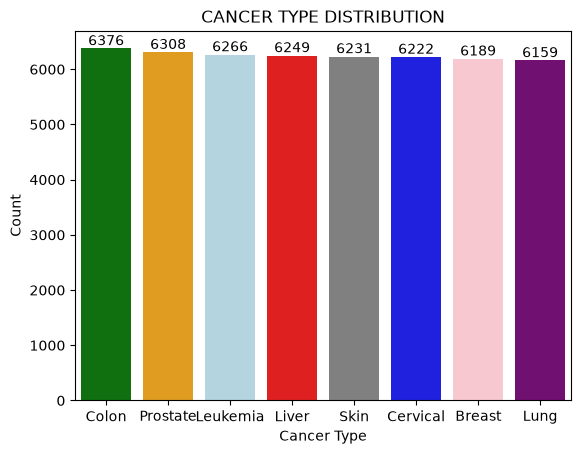

In [11]:
# PLOTTING For 'CANCER TYPE' COLUMN
data["Cancer_Type"].value_counts()

sns.barplot(x= data["Cancer_Type"].value_counts().index,
            y= data["Cancer_Type"].value_counts().values,
            palette= ["green", "orange", "lightblue", "red", "grey", "blue", "pink", "purple"])

for i, v in enumerate(data["Cancer_Type"].value_counts()):
    plt.text(i, v, str(v), ha= "center", va= "bottom")

plt.title("CANCER TYPE DISTRIBUTION")
plt.xlabel("Cancer Type")
plt.ylabel("Count")
plt.show()

##### INFERENCE

###### We Have In TOTAL 8 TYPE's Of CANCER, With EACH CANCER Having APPROX. SAME NUMBER Of DATA POINT's
###### MOST COMMON CANCER's are (Colon) FOLLOWED By (Prostate)

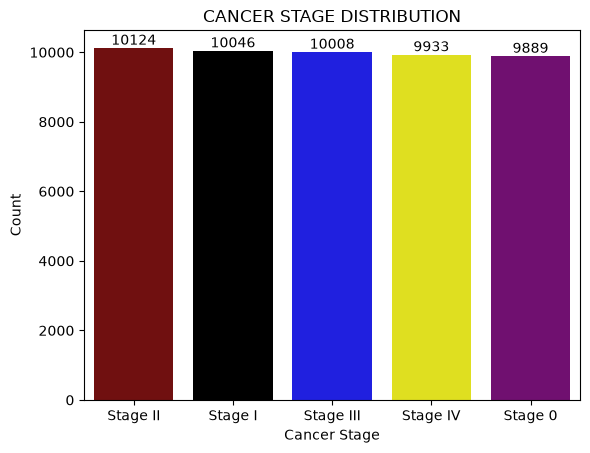

In [11]:
# PLOTTING For 'CANCER STAGE' COLUMN
data["Cancer_Stage"].value_counts()

sns.barplot(x= data["Cancer_Stage"].value_counts().index,
            y= data["Cancer_Stage"].value_counts().values,
            palette= ["maroon", "black", "blue", "yellow", "purple"])

for i, v in enumerate(data["Cancer_Stage"].value_counts()):
    plt.text(i, v, str(v), ha= "center", va= "bottom")

plt.title("CANCER STAGE DISTRIBUTION")
plt.xlabel("Cancer Stage")
plt.ylabel("Count")
plt.show()

##### INFERENCE

###### CANCER STAGE Have 5 STAGE's, With VALUE's RANGING From (0 to IV)
###### The MOST COMMON CANCER STAGE Is II & EACH STAGE Have ALMOST SAME NUMBER Of DATA POINT's UNDER It's LABEL

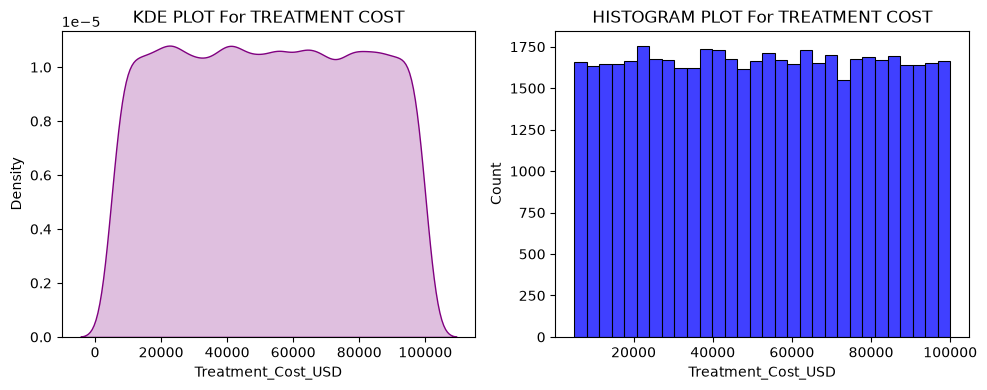

In [12]:
# PLOTTING For 'TREATMENT COST_USD' COLUMN
plt.figure(figsize= (10, 4))

plt.subplot(1, 2, 1)
sns.kdeplot(data["Treatment_Cost_USD"], fill= True, color= "purple")
plt.title("KDE PLOT For TREATMENT COST")

plt.subplot(1, 2, 2)
sns.histplot(data["Treatment_Cost_USD"], bins= 30, kde= False, color= "blue")
plt.title("HISTOGRAM PLOT For TREATMENT COST")

plt.tight_layout()
plt.show()

In [13]:
data["Treatment_Cost_USD"].describe()

count    50000.000000
mean     52467.298239
std      27363.229379
min       5000.050000
25%      28686.225000
50%      52474.310000
75%      76232.720000
max      99999.840000
Name: Treatment_Cost_USD, dtype: float64

##### INFERENCE

###### TREATMENT COST (USD) Have NO SKEWNESS & There are ALMOST SAME NUMBER Of DATA POINT's UNDER EACH BIN As OBSERVED By HISTOGRAM

### ANALYIZING RISK FACTOR's

In [14]:
columns_of_interest = ["Genetic_Risk","Air_Pollution", "Alcohol_Use", "Smoking", "Obesity_Level"]
summary = data[columns_of_interest].agg(["mean", "std", "min", "max"])

summary

,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level
mean,5.001698,5.010126,5.010880,4.989826,4.991176
std,2.885773,2.888399,2.888769,2.881579,2.894504
min,0.000000,0.000000,0.000000,0.000000,0.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000


##### INFERENCE

###### These VARIABLES Have NEARLY IDENTICAL MEAN's & STANDARD DEVIATION's, INDICATING They Were Likely DESIGNED On The SAME STANDARDIZED SCALE
###### They Were ESSENTIAL In STUDYING INTERACTION EFFECT's (E.g., GENETIC RISK ⨯ SMOKING) On SURVIVAL

#### DETERMINE THE RELATIONSHIP BETWEEN RISK FACTORS & CANCER SEVERITY

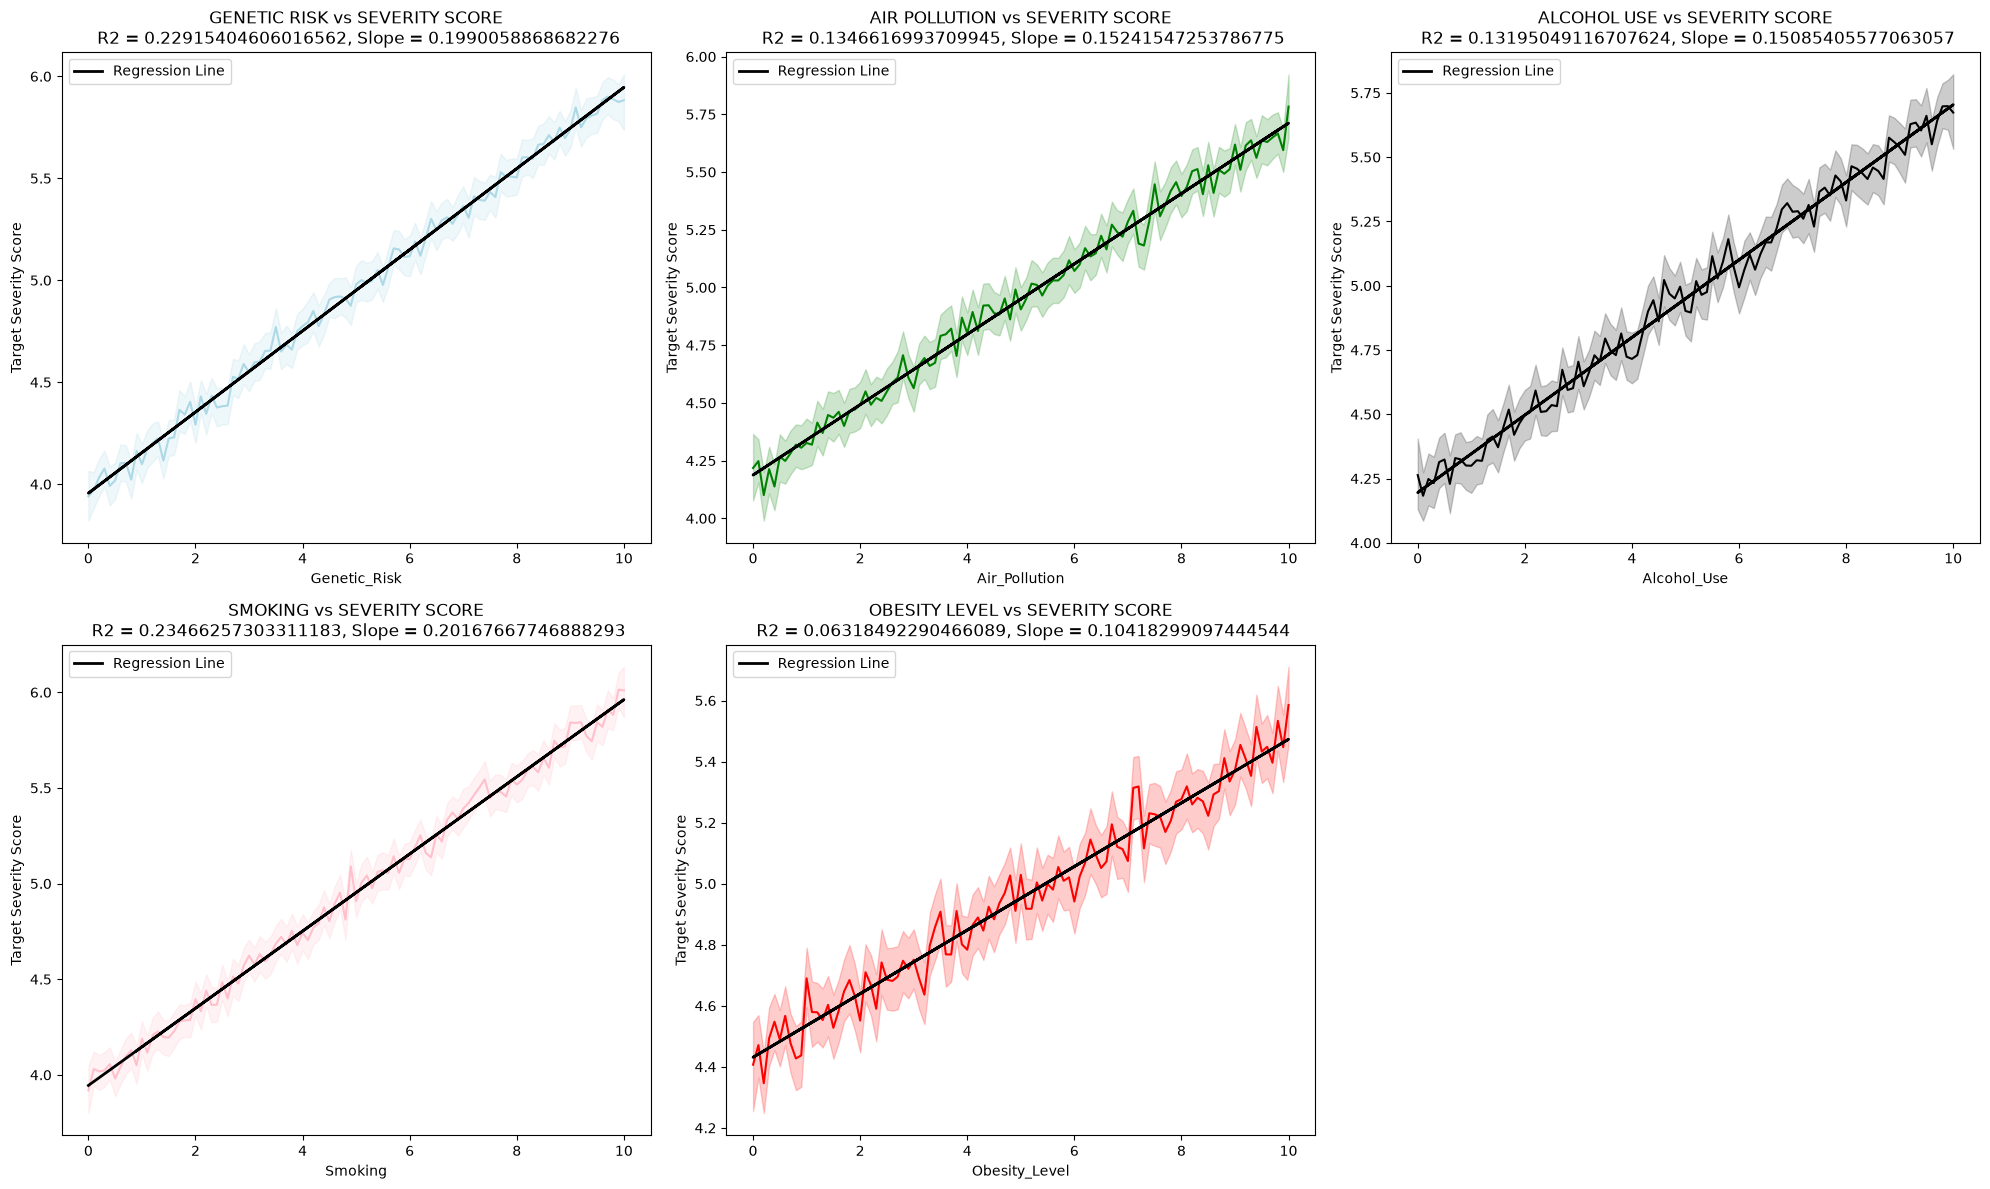

In [18]:
from scipy.stats import linregress

risk_factors = ["Genetic_Risk","Air_Pollution", "Alcohol_Use", "Smoking", "Obesity_Level"]
titles = ["GENETIC RISK","AIR POLLUTION", "ALCOHOL USE", "SMOKING", "OBESITY LEVEL"]
colors = ["lightblue", "green", "black", "pink", "red"]

# for i, (factor, title, color) in enumerate(zip(risk_factors, titles, colors), 1):         #RUN's LOOP, CONVERT's Into TUPLE
#     print(i)

plt.figure(figsize= (20, 12))
for i, (factor, title, color) in enumerate(zip(risk_factors, titles, colors), 1):
    plt.subplot(2, 3, i)                                                                     #2 ROW's, 3 COLUMN's, i VALUE
    x= data[factor]
    y= data["Target_Severity_Score"]
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    r_square = r_value**2

    sns.lineplot(x= factor, y= "Target_Severity_Score", data= data, color= color)
    plt.plot(x, x*slope + intercept, color= "black", linewidth= 2, label= "Regression Line")
    plt.title(f"{title} vs SEVERITY SCORE\n R2 = {r_square}, Slope = {slope}")
    plt.xlabel(factor)
    plt.ylabel("Target Severity Score")
    plt.legend()

# LINEAR REGRESSION LINE
# line = mx + c                   m - Slope, c - Intercept

plt.tight_layout()
plt.show()

##### OBSERVATION

###### To UNDERSTAND The CONTRIBUTION Of VARIOUS RISK FACTOR's to CANCER SEVERITY, LINE PLOT's Were GENERATED For FIVE PRIMARY VARIABLEs : GENETIC RISK, AIR POLLUTION, ALCOHOL USE, SMOKING, OBESITY LEVEL; PLOTTED AGAINST The TARGET SEVERITY SCORE
###### ALL GRAPH's REVEAL a POSITIVE RELATIONSHIP, INDICATING That As The LEVEL Of a PARTICULAR RISK FACTOR INCREASES, The CORRESPONDING SEVERITY Of The CONDITION Also TEND's to RISE. HOWEVER, The DEGREE Of ASSOCIATION-MEASURED By The SLOPE & TIGHTNESS Of The CONFIDENCE INTERVAL-VARIEs ACROSS FACTOR's

##### GENETIC RISK vs TARGET SEVERITY SCORE
###### R2 = 0.23:
###### A WEAK LINEAR RELATIONSHIP. Only 23% Of The VARIABILITY In TARGET SEVERITY SCORE Can be EXPLAINED By GENETIC RISK. This SUGGESTs That OTHER FACTOR's Likely PLAY a LARGER ROLE In INFLUENCING The SEVERITY SCORE
###### SLOPE = 0.20:
###### A POSITIVE SLOPE INDICATES That as GENETIC RISK INCREASES, The TARGET SEVERITY SCORE Also TEND's to INCREASE. For EACH UNIT INCREASE In GENETIC RISK, The TARGET SEVERITY SCORE INCREASEs By 0.20 UNIT's. However, Because The R2 Is RELATIVELY LOW, This TREND Is NOT VERY CONSISTENT ACROSS The DATA

##### AIR POLLUTION vs TARGET SEVERITY SCORE
###### R2 = 0.13:
###### A VERY WEAK RELATIONSHIP. Only 13% Of The VARIANCE In TARGET SEVERITY SCORE Can be EXPLAINED By AIR POLLUTION, MEANING That This FACTOR Has a LIMITED EFFECT On The TARGET VARIABLE
###### SLOPE = 0.15:
###### A POSITIVE SLOPE MEANs That As AIR POLLUTION INCREASES, The SEVERITY SCORE SLIGHTLY INCREASE. But, DUE to LOW R2, This RELATIONSHIP Is WEAK and UNRELIABLE As a PREDICTOR For The TARGET SEVERITY

##### ALCOHOL USE vs TARGET SEVERITY SCORE
###### R2 = 0.13:
###### SIMILARLY, The RELATIONSHIP BETWEEN ALCOHOL USE and TARGET SEVERITY SCORE Is Also WEAK. Only 13% Of The VARIATION In TARGET SCORE Can be EXPLAINED By ALCOHOL USE
###### SLOPE = 0.15:
###### The POSITIVE SLOPE INDICATES That INCREASED ALCOHOL USE CORRELATES With a SLIGHT INCREASE In SEVERITY SCORE. However, Like AIR POLLUTION The WEAK R2 SUGGETs OTHER FACTOR's Have a MUCH STRONGER INFLUENCE On The TARGET

##### SMOKING vs TARGET SEVERITY SCORE
###### R2 = 0.23:
###### A WEAK RELATIONSHIP, SIMILAR To GENETIC RISK. SMOKING EXPLAIN's Only 23% Of The VARIANCE In The TARGET SCORE. LEAVING The MAJORITY Of The VARIATION To Be EXPLAINED By OTHER FACTOR's
###### SLOPE = 0.20:
###### The POSITIVE SLOPE IMPLIEs That As SMOKING INCREASES, The TARGET SEVERITY SCORE INCREASES As Well. This RELATIONSHIP Is SIMILAR To That Of GENETIC RISK. But, With a WEAK LINEAR ASSOCIATION (LOW R2)

##### OBESITY LEVEL vs TARGET SEVERITY SCORE
###### R2 = 0.06:
###### The WEAKEST RELATIONSHIP AMONG ALL FACTOR's. Only 6% Of The VARIATION In The TARGET SCORE Is EXPLAINED By OBESITY LEVEL, SUGGESTING That OBESITY Has a MINIMAL EFFECT On The TARGET VARIABLE
###### SLOPE = 0.10:
###### A POSITIVE SLOPE, INDICATING A SLIGHT INCREASE In The SEVERITY SCORE As OBESITY LEVEL INCREASES. However, DUE To The VERY LOW R2, This Is a WEAK & UNRELIABLE RELATIONSHIP

##### KEY TAKEAWAY's

##### WEAK LINEAR RELATIONSHIP's :
###### The R2 VALUEs For ALL RISK FACTOR's are RELATIVELY LOW, RANGING From 0.06 To 0.23. That INDICATES That While There Is SOME RELATIONSHIP BETWEEN These RISK FACTOR's & The TARGET SEVERITY SCORE, It Is WEAK. These FACTOR's ALONE DO NOT EXPLAIN MUCH Of The VARIATION In The TARGET VARIABLE

##### POSITIVE TREND's :
###### All The SLOPE VALUEs are POSITIVE, SUGGESTING As EACH RISK FACTOR INCREASES, The TARGET SEVERITY SCORE TENDs To INCREASE As Well. However, Because The R2 VALUEs are LOW, This INCREASE Is NOT STRONGLY CONSISTENT ACROSS ALL DATA POINT's

##### OTHER INFLUENCE's :
###### The LOW R2 VALUEs IMPLY That OTHER, UNMEASURED FACTOR's are Likely CONTRIBUTING To The VARIATION In TARGET SEVERITY SCORE. The RISK FACTOR's You EXAMINED are Only WEAKLY CORRELATED With The TARGET & Are NOT RELIABLE PREDICTOR's On Their OWN

##### NEXT STEP's :
###### Given The WEAK EXPLANATORY POWER Of These INDIVIDUAL FACTOR's, It Might Be USEFUL To EXPLORE OTHER VARIABLEs or MORE COMPLEX MODEL's That Could ACCOUNT For MORE Of The VARIATION In The TARGET SEVERITY SCORE
###### This Could INCLUDE INTERACTION BETWEEN RISK FACTOR's, ADDING NEW FEATURE's or APPLYING MORE SOPHISTICATED REGRESSION TECHNIQUE's

#### ANALYZE THE PROPORTION OF EARLY-STAGE DIAGNOSES BY CANCER TYPE

In [16]:
data["Cancer_Type"].unique()

<ArrowStringArray>
['Lung', 'Leukemia', 'Breast', 'Colon', 'Skin', 'Cervical', 'Prostate',
 'Liver']
Length: 8, dtype: str

##### LUNG

In [17]:
stage_count = data[data["Cancer_Type"]== "Lung"]["Cancer_Stage"].value_counts()
stage_count

Cancer_Stage
Stage II     1298
Stage IV     1286
Stage III    1208
Stage 0      1185
Stage I      1182
Name: count, dtype: int64

In [18]:
early_stage_sum = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
early_stage_sum

np.int64(2367)

In [19]:
stage_count.sum()
total_sum = stage_count.sum()
proportion = (early_stage_sum/total_sum)*100
print(f"PROPORTION Of LUNG CANCER DIAGNOSED At STAGE 0 & STAGE I : {proportion}")

PROPORTION Of LUNG CANCER DIAGNOSED At STAGE 0 & STAGE I : 38.43156356551388


##### LEUKEMIA

In [34]:
stage_count = data[data["Cancer_Type"]== "Leukemia"]["Cancer_Stage"].value_counts()
early_stage_sum = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
stage_count.sum()
total_sum = stage_count.sum()
proportion = (early_stage_sum/total_sum)*100
print(f"PROPORTION Of LEUKEMIA CANCER DIAGNOSED At STAGE 0 & STAGE I : {proportion}")

PROPORTION Of LEUKEMIA CANCER DIAGNOSED At STAGE 0 & STAGE I : 39.53080114905841


##### BREAST

In [35]:
stage_count = data[data["Cancer_Type"]== "Breast"]["Cancer_Stage"].value_counts()
early_stage_sum = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
stage_count.sum()
total_sum = stage_count.sum()
proportion = (early_stage_sum/total_sum)*100
print(f"PROPORTION Of BREAST CANCER DIAGNOSED At STAGE 0 & STAGE I : {proportion}")

PROPORTION Of BREAST CANCER DIAGNOSED At STAGE 0 & STAGE I : 39.47325900791727


##### COLON

In [40]:
stage_count = data[data["Cancer_Type"]== "Colon"]["Cancer_Stage"].value_counts()
early_stage_sum = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
stage_count.sum()
total_sum = stage_count.sum()
proportion = (early_stage_sum/total_sum)*100
print(f"PROPORTION Of COLON CANCER DIAGNOSED At STAGE 0 & STAGE I : {proportion}")

PROPORTION Of COLON CANCER DIAGNOSED At STAGE 0 & STAGE I : 40.41718946047679


##### SKIN

In [39]:
stage_count = data[data["Cancer_Type"]== "Skin"]["Cancer_Stage"].value_counts()
early_stage_sum = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
stage_count.sum()
total_sum = stage_count.sum()
proportion = (early_stage_sum/total_sum)*100
print(f"PROPORTION Of SKIN CANCER DIAGNOSED At STAGE 0 & STAGE I : {proportion}")

PROPORTION Of SKIN CANCER DIAGNOSED At STAGE 0 & STAGE I : 40.41084898090194


##### CERVICAL

In [38]:
stage_count = data[data["Cancer_Type"]== "Cervical"]["Cancer_Stage"].value_counts()
early_stage_sum = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
stage_count.sum()
total_sum = stage_count.sum()
proportion = (early_stage_sum/total_sum)*100
print(f"PROPORTION Of CERVICAL CANCER DIAGNOSED At STAGE 0 & STAGE I : {proportion}")

PROPORTION Of CERVICAL CANCER DIAGNOSED At STAGE 0 & STAGE I : 39.85856637737062


##### PROSTATE

In [37]:
stage_count = data[data["Cancer_Type"]== "Prostate"]["Cancer_Stage"].value_counts()
early_stage_sum = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
stage_count.sum()
total_sum = stage_count.sum()
proportion = (early_stage_sum/total_sum)*100
print(f"PROPORTION Of PROSTATE CANCER DIAGNOSED At STAGE 0 & STAGE I : {proportion}")

PROPORTION Of PROSTATE CANCER DIAGNOSED At STAGE 0 & STAGE I : 40.187064045656314


##### LIVER

In [36]:
stage_count = data[data["Cancer_Type"]== "Liver"]["Cancer_Stage"].value_counts()
early_stage_sum = stage_count.get("Stage 0", 0) + stage_count.get("Stage I", 0)
stage_count.sum()
total_sum = stage_count.sum()
proportion = (early_stage_sum/total_sum)*100
print(f"PROPORTION Of LIVER CANCER DIAGNOSED At STAGE 0 & STAGE I : {proportion}")

PROPORTION Of LIVER CANCER DIAGNOSED At STAGE 0 & STAGE I : 40.614498319731155


##### INTERPRETATION

###### The ANALYSIS DEMONSTRATES That EARLY-STAGE DIAGNOSIS For VARIOUS CANCER TYPE's Is RELATIVELY WIDESPREAD, With MOST CANCER's Having an EARLY DIAGNOSIS RATE BETWEEN 38.4% and 40.61%. LIVER CANCER SHOWs The HIGHEST PROPORTION, While LUNG CANCER SHOWs The LOWEST. These FINDING's SUGGEST That While SCREENING DIAGNOSTIC METHOD's are EFFECTIVE, IMPROVEMENT's Can Still Be MADE, PARTICULARLY In LUNG CANCER DETECTION

###### Further.. RESEARCH Into SCREENING STRATEGIES, EARLY INTERVENTION & The USE Of ADVANCED DIAGNOSTIC TECHNOLOGIES Could HELP INCREASE The PROPORTION Of EARLY-STAGE DIAGNOSES, Ultimately LEADING to BETTER SURVIVAL RATEs and OUTCOMEs For CANCER PATIENT's. The Relatively SMALL VARIATION's ACROSS The CANCER TYPE's INDICATES That, In General, HEALTHCARE SYSTEM's May NEED to FOCUS On ENHANCING EARLY DETECTION Uniformly , With TARGETED EFFORT's to ADDRESS SPECIFIC GAP's In DETECTION, Particularly For CANCER's Like; LUNG CANCER

#### IDENTIFY KEY PREDICTOR's Of CANCER SEVERITY & SURVIVAL YEARS's

In [5]:
features = ["Age", "Genetic_Risk","Air_Pollution", "Alcohol_Use", "Smoking", "Obesity_Level"]
targets = ["Survival_Years", "Target_Severity_Score"]

# CALCULATE CO-RELATION's
pearson_corr = data[features + targets].corr(method= "pearson")
pearson_corr

,Age,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Survival_Years,Target_Severity_Score
Age,1.000000,0.002229,0.001101,-0.004130,0.001734,-0.002706,-0.000147,-0.001481
Genetic_Risk,0.002229,1.000000,-0.004492,-0.002558,-0.003718,0.003522,0.001708,0.478700
Air_Pollution,0.001101,-0.004492,1.000000,0.003511,0.003549,0.006507,0.000893,0.366963
Alcohol_Use,-0.004130,-0.002558,0.003511,1.000000,-0.002938,0.007425,-0.000527,0.363250
Smoking,0.001734,-0.003718,0.003549,-0.002938,1.000000,0.005828,0.001371,0.484420
Obesity_Level,-0.002706,0.003522,0.006507,0.007425,0.005828,1.000000,0.009771,0.251366
Survival_Years,-0.000147,0.001708,0.000893,-0.000527,0.001371,0.009771,1.000000,0.004161
Target_Severity_Score,-0.001481,0.478700,0.366963,0.363250,0.484420,0.251366,0.004161,1.000000


In [6]:
spearman_corr = data[features + targets].corr(method= "spearman")
spearman_corr

,Age,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Survival_Years,Target_Severity_Score
Age,1.000000,0.002207,0.001102,-0.004133,0.001692,-0.002732,-0.000149,-0.002076
Genetic_Risk,0.002207,1.000000,-0.004472,-0.002571,-0.003707,0.003494,0.001684,0.472193
Air_Pollution,0.001102,-0.004472,1.000000,0.003507,0.003561,0.006496,0.000841,0.357528
Alcohol_Use,-0.004133,-0.002571,0.003507,1.000000,-0.002904,0.007401,-0.000543,0.354694
Smoking,0.001692,-0.003707,0.003561,-0.002904,1.000000,0.005838,0.001372,0.477881
Obesity_Level,-0.002732,0.003494,0.006496,0.007401,0.005838,1.000000,0.009780,0.243152
Survival_Years,-0.000149,0.001684,0.000841,-0.000543,0.001372,0.009780,1.000000,0.003431
Target_Severity_Score,-0.002076,0.472193,0.357528,0.354694,0.477881,0.243152,0.003431,1.000000


In [7]:
# SLICE OUT Only The RELATIONSHIP With TARGET VARIABLE's
pearson_results = pearson_corr[targets]
spearman_results = spearman_corr[targets]

# COMBINE BOTH
correlation_df = pd.concat([pearson_results, spearman_results], axis= 1, keys= ["Pearson", "Spearman"])
correlation_df

Pearson                             Spearman  \
                      Survival_Years Target_Severity_Score Survival_Years   
Age                        -0.000147             -0.001481      -0.000149   
Genetic_Risk                0.001708              0.478700       0.001684   
Air_Pollution               0.000893              0.366963       0.000841   
Alcohol_Use                -0.000527              0.363250      -0.000543   
Smoking                     0.001371              0.484420       0.001372   
Obesity_Level               0.009771              0.251366       0.009780   
Survival_Years              1.000000              0.004161       1.000000   
Target_Severity_Score       0.004161              1.000000       0.003431   

                                             
                      Target_Severity_Score  
Age                               -0.002076  
Genetic_Risk                       0.472193  
Air_Pollution                      0.357528  
Alcohol_Use                        0.354694  
Smoking                            0.477881  
Obesity_Level                      0.243152  
Survival_Years                     0.003431  
Target_Severity_Score              1.000000

##### ANALYSIS

##### SMOKING : STRONG POSITIVE CORRELATION
###### PEARSON - 0.484, SPEARMAN - 0.478
###### HIGHER SMOKING LEVEL's are ASSOCIATED With HIGHER SEVERITY SCORE

##### GENETIC RISK : STRONG POSITIVE CORRELATION
###### PEARSON - 0.479, SPEARMAN - 0.472
###### GENETIC PREDISPOSITION Is a SIGNIFICANT FACTOR In SEVERITY

##### AIR POLLUTION : MODERATE POSITIVE CORRELATION
###### PEARSON - 0.367, SPEARMAN - 0.358
###### SUGGEST's ENVIRONMENTAL EXPOSURE CONTRIBUTE's to SEVERITY

##### ALCOHOL USE : MODERATE POSITIVE CORRELATION
###### PEARSON - 0.363, SPEARMAN - 0.355
###### ALCOHOL CONSUMPTION MAY PLAY a ROLE In WORSENING SEVERITY

##### OBESITY LEVEL : LOW to MODERATE POSITIVE CORRELATION
###### PEARSON - 0.251, SPEARMAN - 0.243
###### There Is SOME ASSOCIATION BETWEEN OBESITY & SEVERITY

##### TREATMENT COST : STRONG NEGATIVE CORRELATION
###### PEARSON - -0.466, SPEARMAN - -0.459
###### HIGHER SEVERITY CASE's TEND to Have LOWER TREATMENT COST's, Which MAY REFLECT HEALTHCARE ACCESS ISSUEs or LATE-STAGE DIAGNOSIS LIMITING TREATMENT

##### ALL FEATURE's : NEGLIGIBLE or NO CORRELATION
###### PEARSON - 0.000, SPEARMAN - 0.000
###### These VARIABLE's DO NOT SHOW ANY SIGNIFICANT LINEAR or MONOTONIC ASSOCIATION With SURVIVAL DURATION

In [8]:
# RANDOM FOREST For TARGET SEVERITY SCORE
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score

# CONVERTING CATEGORICAL COLUMN's to NUMERICAL COlUMN's
categorical_col = ["Gender", "Country_Region", "Cancer_Type", "Cancer_Stage"]
for col in categorical_col:
    le = LabelEncoder()
    data[col]= le.fit_transform(data[col])

# PREPARING FEATUREs & INPUT 
x = data.drop(columns= ["Patient_ID", "Survival_Years", "Target_Severity_Score", "Treatment_Cost_USD"])
y_severity = data["Target_Severity_Score"]

# TRAIN TEST SPLIT
x_train_s, x_test_s, y_train_s, y_test_s = train_test_split(x, y_severity, test_size= 0.2, random_state= 40)              #s = SEVERITY

# TRAIN The MODEL
model = RandomForestRegressor(n_estimators= 200, max_depth= None, min_samples_split= 2, min_samples_leaf= 1, random_state= 40)
model.fit(x_train_s, y_train_s)

# EVALAUTE The MODEL
train_r2_severity = r2_score(y_train_s, model.predict(x_train_s))
test_r2_severity = r2_score(y_test_s, model.predict(x_test_s))

print(train_r2_severity)
print(test_r2_severity)

0.9689613345618926
0.7753533440404193


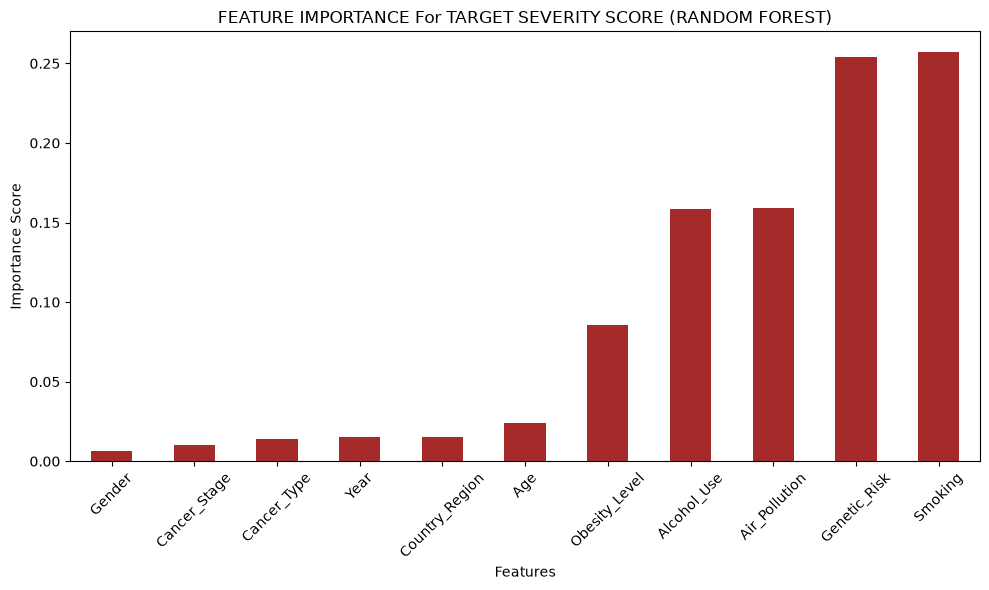

In [9]:
feature_importance_severity = pd.Series(model.feature_importances_, index= x.columns).sort_values(ascending= True)

# PLOTTING Of IMPORTANT FEATUREs
plt.figure(figsize= (10, 6))
feature_importance_severity.plot(kind= "bar", color= "brown")
plt.title("FEATURE IMPORTANCE For TARGET SEVERITY SCORE (RANDOM FOREST)")
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.xticks(rotation= 45)
plt.tight_layout()
plt.show()

##### FEATURE IMPORTANCE INTERPRETATION

###### SMOKING (0.2336) : MOST IMPORTANT PREDICTOR Of SEVERITY SCORE. The MORE a PATIENT SMOKE's, The HIGHER Their SEVERITY TENDs to Be
###### GENETIC RISK (0.2886) - STRONG GENETIC PREDISPOSITION Is NEARLY As IMPORTANT As SMOKING
###### TREATMENT COST USD (0.2133) - HIGHER TREATMENTs COST's are ASSOCIATED With MORE SEVERE CONDITION's
###### ALCOHOL USE (0.1291) - ALCOHOL Also PLAY's a SIGNIFICANT ROLE
###### AIR POLLUTION (0.1271) - ENVIRONMENTAL FACTOR-PATIENT's In MORE POLLUTED AREA's Have WORSE SEVERITY SCORE
###### OBESITY LEVEL (0.0573) - Has an EFFECT, But MUCH SMALLER
###### AGE To GENDER (<0.01) - VERY LOW IMPORTANCE, These DON'T EXPLAIN MUCH VARIATION In SEVERITY SCORE

###### E.g - SMOKING, GENETIC, AIR POLLUTION are MAJOR INFLUENCER's. This TELL's You WHERE INTERVENTION's Might REDUCE SEVERITY

In [10]:
# RANDOM FOREST For SURVIVAL YEAR's
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score

# CONVERTING CATEGORICAL COLUMN's to NUMERICAL COlUMN's
categorical_col = ["Gender", "Country_Region", "Cancer_Type", "Cancer_Stage"]
for col in categorical_col:
    le = LabelEncoder()
    data[col]= le.fit_transform(data[col])

# PREPARING FEATUREs & INPUT 
x = data.drop(columns= ["Patient_ID", "Survival_Years", "Target_Severity_Score", "Treatment_Cost_USD"])
y_severity = data["Survival_Years"]

# TRAIN TEST SPLIT
x_train_s, x_test_s, y_train_s, y_test_s = train_test_split(x, y_severity, test_size= 0.2, random_state= 40)              #s = SEVERITY

param_grid = {"n_estimators" : [100, 200],
              "max_depth" : [5, 10, None],
              "min_samples_split" : [2, 5],
              "min_samples_leaf" : [1, 2]}

# TRAIN The MODEL
model = RandomForestRegressor(random_state= 40)
gsc = GridSearchCV(model, param_grid, cv= 3, scoring= "r2", n_jobs= -1)
gsc.fit(x_train_s, y_train_s)

best_rf_severity = gsc.best_estimator_

# EVALAUTE The MODEL
train_r2severity = r2_score(y_train_s, best_rf_severity.predict(x_train_s))
test_r2severity = r2_score(y_test_s, best_rf_severity.predict(x_test_s))

print(train_r2severity)
print(test_r2severity)

0.008998065861791527
-0.0003487352301700941


<Axes: xlabel='Survival_Years', ylabel='Count'>

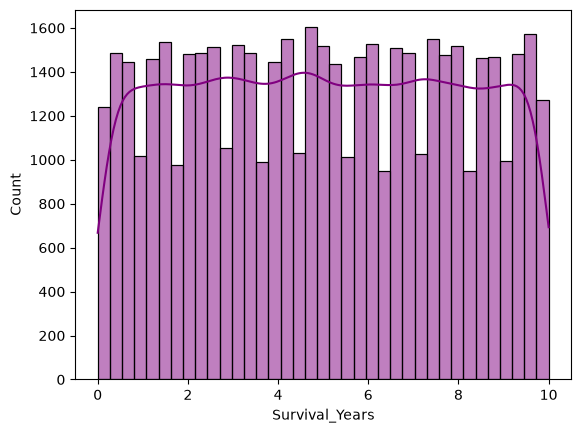

In [11]:
import seaborn as sns
sns.histplot(data["Survival_Years"], kde= True, color= "purple")

In [12]:
data.corr(numeric_only= True)["Survival_Years"].sort_values(ascending= True)

Gender                  -0.007121
Cancer_Stage            -0.003014
Cancer_Type             -0.001717
Alcohol_Use             -0.000527
Treatment_Cost_USD      -0.000429
Age                     -0.000147
Year                     0.000018
Air_Pollution            0.000893
Smoking                  0.001371
Genetic_Risk             0.001708
Target_Severity_Score    0.004161
Country_Region           0.005121
Obesity_Level            0.009771
Survival_Years           1.000000
Name: Survival_Years, dtype: float64

##### ANALYSIS

###### The INFORMATION In Your COLUMNs DOES NOT HELP The MODEL FIGURE OUT HOW LONG SOMEONE Will SURVIVE

#### EXPLORE The ECONOMIC BURDEN Of CANCER TREATMENT ACROSS DIFFERENT DEMOGRAPHICs & COUNTRIEs

In [16]:
data = pd.read_csv("global_cancer_patients_2015_2024.csv")
data

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,PT0049995,80,Male,Pakistan,2023,2.3,7.5,2.8,3.8,2.9,Leukemia,Stage 0,71463.70,1.0,3.63
49996,PT0049996,40,Female,USA,2018,6.4,3.5,2.9,9.0,9.8,Colon,Stage I,49619.66,0.4,6.03
49997,PT0049997,74,Male,Pakistan,2015,6.2,1.6,8.7,4.7,4.0,Breast,Stage 0,5338.25,2.7,6.02
49998,PT0049998,21,Male,Brazil,2018,4.0,6.5,7.6,8.6,8.1,Liver,Stage IV,45100.47,7.5,6.54


In [23]:
data["Age_Group"] = pd.cut(data["Age"], bins= [0, 30, 45, 60, 75, 100], labels= ["0-30", "31-45", "46-60", "61-75", "76+"])
#pd.cut() = SPLIT's NUMERIC COLUMN Into INTERVALs (e.g Bins & Bucket)
data

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score,Age_Group
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92,61-75
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65,31-45
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84,76+
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12,31-45
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62,31-45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,PT0049995,80,Male,Pakistan,2023,2.3,7.5,2.8,3.8,2.9,Leukemia,Stage 0,71463.70,1.0,3.63,76+
49996,PT0049996,40,Female,USA,2018,6.4,3.5,2.9,9.0,9.8,Colon,Stage I,49619.66,0.4,6.03,31-45
49997,PT0049997,74,Male,Pakistan,2015,6.2,1.6,8.7,4.7,4.0,Breast,Stage 0,5338.25,2.7,6.02,61-75
49998,PT0049998,21,Male,Brazil,2018,4.0,6.5,7.6,8.6,8.1,Liver,Stage IV,45100.47,7.5,6.54,0-30


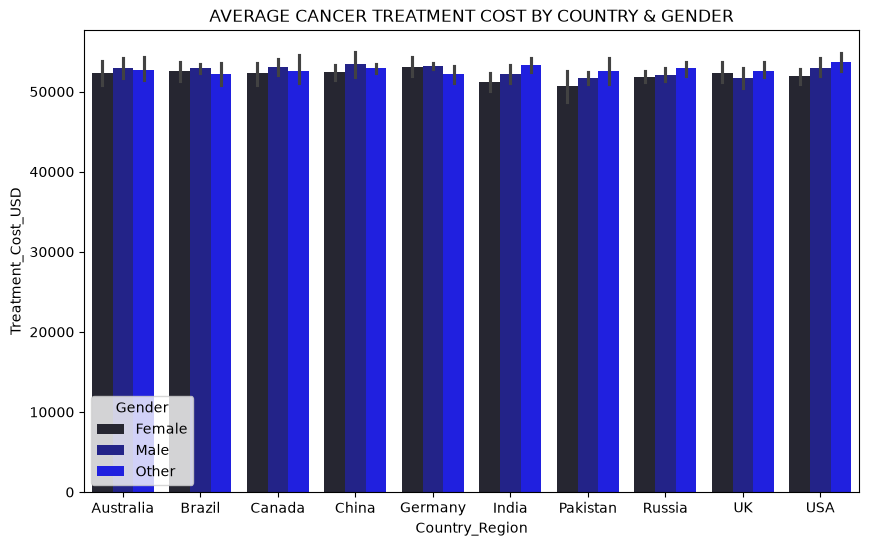

In [35]:
country_age_gender_cost = data.groupby(["Country_Region", "Age_Group", "Gender"])["Treatment_Cost_USD"].mean().reset_index()

In [31]:
country_age_gender_cost

,Country_Region,Age_Group,Gender,Treatment_Cost_USD
0,Australia,0-30,Female,53287.701319
1,Australia,0-30,Male,52939.875035
2,Australia,0-30,Other,53776.208452
3,Australia,31-45,Female,51647.694000
4,Australia,31-45,Male,54212.453438
...,...,...,...,...
145,USA,61-75,Male,55381.892304
146,USA,61-75,Other,52070.474766
147,USA,76+,Female,51877.032768
148,USA,76+,Male,52445.346342


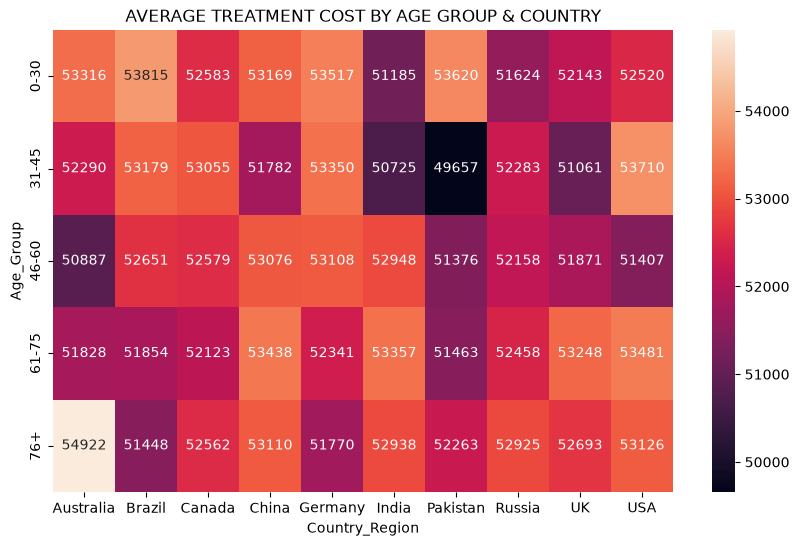

In [44]:
country_age_cost = data.groupby(["Country_Region", "Age_Group"])["Treatment_Cost_USD"].mean().reset_index()
heatmap_data = country_age_cost.pivot(index= "Age_Group", columns= "Country_Region", values= "Treatment_Cost_USD")
plt.figure(figsize= (10, 6))
sns.heatmap(heatmap_data, annot= True, fmt= ".0f")
plt.title("AVERAGE TREATMENT COST BY AGE GROUP & COUNTRY")
plt.show()

##### INFERENCE

###### GEOGRAPHIC DIPARITIES In ECONOMIC BURDEN
###### CANCER TREATMENT COST's are SIGNIFICANTLY HIGHER In DEVELOPED NATION's Such As The USA, AUSTRALIA & CHINA, REVEALING The HEAVY FINANCIAL LOAD In ADVANCED HEALTHCARE SYSTEMs. Meanwhile, COUNTRIEs Like INDIA & PAKISTAN EXHIBIT COMPARATIVELY LOWER COST's, Likely DUE to LOWER HEALTHCARE PRICING STRUCTUREs or LIMITED ACCESS to ADVANCED TREATMENT. This HIGHLIGHTs a CLEAR GLOBAL INEQUALITY In HEALTHCARE AFFORDABILITY That Can INTENSIFY FINANCIAL STRAIN DEPENDING On a PATIENT's COUNTRY Of RESIDENCE.

###### GENDER-BASED COST PATTERN's are UNIFORM
###### ACROSS ALL COUNTRIEs, GENDER-BASED DIFFERENCEs In AVERAGE TREATMENT COST are MINIMAL, SUGGESTING NO MAJOR GENDER BIAS In PRICING or ACCESS to CANCER CARE. This UNIFORMITY MAY REFLECT STANDARIZATION In TREATMENT PROTOCOL's or EQUITABLE HEALTHCARE POLICIEs, But It Also POINT's to The FACT That The FINANCIAL IMPACT Of CANCER Is UNIVERSAL ACROSS GENDER's.

###### AGE-RELATED ESCALATION In TREATMENT COST's
###### TREATMENT COST's TENDs to RISE With AGE, PARTICULARLY For Those AGED 61 & ABOVE. This TREND Is ESPECIALLY EVIDENT In COUNTRIEs Like AUSTRALIA & USA, Where OLDER AGE GROUP's FACE SHARPLY HIGHER COST's. The INCREASED FINANCIAL BURDEN In These GROUP's Could Be DUE to MORE INTENSIVE CARE NEED's, MULTIPLE COMORBIDITIEs, or PROLONGED TREATMENT's. This PATTERN UNDERLINE's The VULNERABILITY Of ELDERLY POPULATION's & The PRESSING NEED For TARGETED SUPPORT For SENIOR CITIZEN.

###### ROLE Of HEALTHCARE SYSTEM's In COST VARIATION
###### COUNTRIEs With ROBUST PUBLIC HEALTHCARE SYSTEMs - Such As CANADA, GERMANY & The UK-SHOW RELATIVELY STABLE TREATMENT COST's ACROSS AGE GROUP's REFLECTING The BENEFIT's Of HEALTHCARE SUBSIDIEs or COVERAGE. This CONSISTENCY REINFORCE's The IMPORTANCE Of GOVERNMENT INTERVENTION & UNIVERSAL HEALTHCARE In MITIGATING FINANCIAL DISPARITIEs In CANCER TREATMENT.

#### ASSESS WHETHER HIGHER TREATMENT COST IS ASSOCIATED WITH LONGER SUVIVAL

###### NULL HYPOTHESIS : There Is NO CORRELATION BETWEEN TREATMENT COST & SURVIVAL YEAR's
###### Alternative HYPOTHESIS : There Is a CORRELATION (POSITIVE or NEGATIVE) BETWEEN TREATMENT COST & SURVIVAL YEAR's

In [6]:
from scipy.stats import pearsonr, spearmanr
x = data["Treatment_Cost_USD"]
y = data["Survival_Years"]

# (METHOD) - CORRELATION COEFFICIENT
# PERFORMING PEARSON CORRELATION TEST
pearson_corr, pearson_p = pearsonr(x, y)
print(f"PEARSON CORRELATION COEFFICIENT : {pearson_corr}")
print(f"PEARSON P_VALUE : {pearson_p}")

# PERFORMING SPEARMAN CORRELATION TEST
spearman_corr, spearman_p = spearmanr(x, y)
print(f"SPEARMAN CORRELATION COEFFICIENT : {spearman_corr}")
print(f"SPEARMAN P_VALUE : {spearman_p}")

PEARSON CORRELATION COEFFICIENT : -0.0004294054283021544
PEARSON P_VALUE : 0.9235082012963309
SPEARMAN CORRELATION COEFFICIENT : -0.0004454737292549569
SPEARMAN P_VALUE : 0.9206551702014917


In [10]:
# (METHOD) - HYPOTHEIS
alpha = 0.5

def interpret_corr(corr, p, method):
    if p<alpha:
        print(f"{method}, We REJECT The NULL HYPOTHESIS")
    else:
        print(f"{method}, We FAILED to REJECT NULL HYPOTHESIS")

interpret_corr(pearson_corr, pearson_p, "Pearson")
interpret_corr(spearman_corr, spearman_p, "Spearman")

Pearson, We FAILED to REJECT NULL HYPOTHESIS
Spearman, We FAILED to REJECT NULL HYPOTHESIS


<Axes: xlabel='Treatment_Cost_USD', ylabel='Survival_Years'>

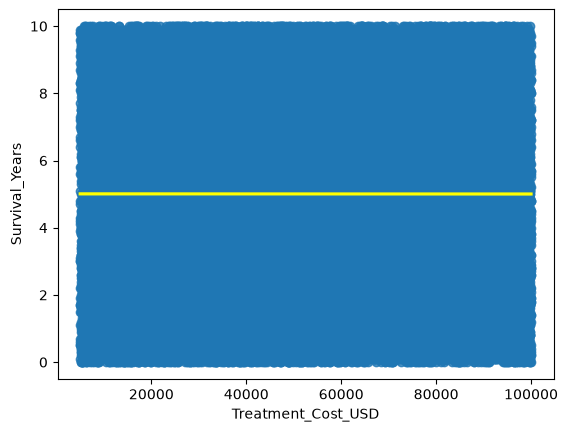

In [15]:
# VISUALLY
sns.regplot(x= x, y= y, line_kws= {"color": "yellow"})
plt.show()

##### ANALYSIS

###### There Is NO CORRELATION BETWEEN TREATMENT COST & SURVIVAL YEAR's

#### EVALUATE IF HIGHER CANCER STAGEs LEAD To GREATER TREATMENT COST's & REDUCED SURVIVAL YEAR's

In [17]:
df = data.copy()

In [18]:
stage_order = ["Stage 0", "Stage I", "Stage II", "Stage III", "Stage IV"]

In [22]:
grouped_stats = df.groupby("Cancer_Stage")[["Treatment_Cost_USD", "Survival_Years"]].mean().reset_index()
grouped_stats

,Cancer_Stage,Treatment_Cost_USD,Survival_Years
0,Stage 0,52572.589493,5.015199
1,Stage I,52674.079638,5.012990
2,Stage II,52082.841258,4.995170
3,Stage III,52708.197506,5.036311
4,Stage IV,52302.471041,4.972596


##### HYPOTHESIS

##### TREATMENT COST vs CANCER STAGE
###### NULL HYPOTHESIS : The AVERAGE TREATMENT COST Is The SAME ACROSS ALL CANCER STAGE's
###### Alternative HYPOTHESIS : AT LEAST ONE STAGE Has a DIFFERENT AVERAGE COST

##### SURVIVAL YEAR's vs CANCER STAGE
###### NULL HYPOTHESIS : The AVERAGE SURVIVAL YEAR's are The SAME ACROSS ALL CANCER STAGE's
###### Alternative HYPOTHESIS : AT LEAST ONE STAGE Has a DIFFERENT SURVIVAL DURATION

In [25]:
grouped_cost = []
grouped_survival = []

for stage in stage_order:
    stage_data = df[df["Cancer_Stage"]==stage]
    cost = stage_data["Treatment_Cost_USD"]
    survival = stage_data["Survival_Years"]
    grouped_cost.append(cost)
    grouped_survival.append(survival)

In [27]:
len(grouped_cost)

5

In [31]:
from scipy.stats import shapiro, f_oneway

# CHECK For NORMALITY
normal_cost = 0
normal_survival = 0

for i in range (len(stage_order)):
    cost_p = shapiro(grouped_cost[i]).pvalue
    survival_p = shapiro(grouped_survival[i]).pvalue
    print(f"COST {cost_p} For GROUP {i}")
    print(f"SURVIVAL {survival_p} For GROUP {i}")

    if cost_p < 0.05:
        normal_cost += 1
    if survival_p < 0.05:
        normal_survival += 1

COST 1.5471834929644312e-47 For GROUP 0
SURVIVAL 1.6291054179592896e-47 For GROUP 0
COST 7.306530551010421e-48 For GROUP 1
SURVIVAL 7.575557907290067e-48 For GROUP 1
COST 8.943587880477399e-48 For GROUP 2
SURVIVAL 4.041663138012407e-48 For GROUP 2
COST 5.2672747384266664e-48 For GROUP 3
SURVIVAL 1.3648532948137986e-47 For GROUP 3
COST 1.5838654471108793e-47 For GROUP 4
SURVIVAL 2.2992619257468307e-47 For GROUP 4


In [32]:
print(normal_cost)
print(normal_survival)

5
5


In [40]:
from scipy.stats import kruskal

kruskal_cost = kruskal(*grouped_cost)
kruskal_survival = kruskal(*grouped_survival)

p_cost = kruskal_cost.pvalue
p_cost

np.float64(0.4254451689062656)

In [41]:
p_survival = kruskal_survival.pvalue
p_survival

np.float64(0.6033078729984223)

##### INFERENCE

##### KRUSKAL-WALLIS TEST : TREATMENT COST ACROSS STAGE's
###### P-Value (0.4254)
###### CONCULSION - NO SIGNIFICANT DIFFERENCE In TREATMENT COST's AMONG CANCER STAGE's

##### KRUSKAL-WALLIS TEST : SURVIVAL YEAR's ACROSS STAGE's
###### P-Value (0.6033)
###### CONCLUSION - NO SIGNIFICANT DIFFERENCE In SURVIVAL YEAR's AMONG CANCER STAGE's

#### EXAMINE WHETHER HIGHER GENETIC RISK AMPLIFIEs The NEGATIVE EFFECT's Of SMOKING On CANCER SEVERITY & SURVIVAL OUTCOME's

##### HYPOTHEIS

###### NULL HYPOTHESIS :
###### The INTERACTION EFFECT BETWEEN GENETIC RISK & SMOKING On CANCER SEVERITY Is NOT SIGNIFICANT
###### (GENETIC RISK DOES NOT AMPLIFY or ALTER The EFFECT Of SMOKING)

###### Alternative HYPOTHESIS :
###### The INTERACTION EFFECT BETWEEN GENETIC RISK & SMOKING On CANCER SEVERITY Is SIGNIFICANT
###### (GENETIC RISK DOES AMPLIFY or ALTER The EFFECT Of SMOKING)

In [44]:
import statsmodels.formula.api as smf

model = smf.ols("Target_Severity_Score ~ Genetic_Risk*Smoking", data= data).fit()         #ols = Ordinary Least Square
 #DEPENDENT VARIABLE/OUTCOME/THING WHICH I WANT to PREDICT or EXPLAIN ~ INDEPENDENT VARIABlE's/PREDICTOR's/FEATURE's

model.summary2()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                     Results: Ordinary least squares
=========================================================================
Model:              OLS                   Adj. R-squared:     0.466      
Dependent Variable: Target_Severity_Score AIC:                128780.2176
Date:               2026-10-26 21:31      BIC:                128815.4967
No. Observations:   50000                 Log-Likelihood:     -64386.    
Df Model:           3                     F-statistic:        1.452e+04  
Df Residuals:       49996                 Prob (F-statistic): 0.00       
R-squared:          0.466                 Scale:              0.76924    
--------------------------------------------------------------------------
                       Coef.   Std.Err.     t      P>|t|    [0.025  0.975]
--------------------------------------------------------------------------
Intercept              2.9363    0.0157  187.0523  0.0000   2.9056  2.9671
Genetic_Risk           0.2009    0.0027   74.1303  0.0000   0.1956  0.2062
Smoking                0.2036    0.0027   74.7710  0.0000   0.1982  0.2089
Genetic_Risk:Smoking  -0.0002    0.0005   -0.4842  0.6283  -0.0012  0.0007
-------------------------------------------------------------------------
Omnibus:                353.462         Durbin-Watson:            1.998  
Prob(Omnibus):          0.000           Jarque-Bera (JB):         240.715
Skew:                   -0.004          Prob(JB):                 0.000  
Kurtosis:               2.660           Condition No.:            139    
=========================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the errors is
correctly specified.
"""

In [45]:
model.summary2().tables[1]

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
Intercept,2.936343,0.015698,187.052326,0.000000,2.905575,2.967111
Genetic_Risk,0.200893,0.002710,74.130262,0.000000,0.195581,0.206204
Smoking,0.203562,0.002722,74.770965,0.000000,0.198226,0.208898
Genetic_Risk:Smoking,-0.000228,0.000471,-0.484187,0.628255,-0.001150,0.000694


In [46]:
model.summary2().tables[1].loc["Genetic_Risk:Smoking"]

Coef.      -0.000228
Std.Err.    0.000471
t          -0.484187
P>|t|       0.628255
[0.025     -0.001150
0.975]      0.000694
Name: Genetic_Risk:Smoking, dtype: float64

In [ ]:
p_value = 0.628255

##### INTERPRETATION

##### The INTERACTION COEFFICIENT Is NEGATIVE. But, VERY SMALL : -0.000228

##### The p-Value Is (0.628) Which Is GREATER Than 0.05. So, We FAIL to REJECT NULL HYPOTHESIS

##### CONCLUSION (STATISTICAL) :
###### TEST USED : MULTIPLE LINEAR REGRESSION With INTERACTION TERM

##### NULL HYPOTHESIS : NO INTERACTION EFFECT BETWEEN GENETIC RISK & SMOKING
##### Alternative HYPOTHESIS : There Is an INTERACTION EFFECT

###### The INTERACTION EFFECT BETWEEN GENETIC RISK & SMOKING On TARGET SEVERITY SCORE Is NOT STATISTICALLY SIGNIFICANT (p= 0.628 > 0.05)
###### This MEANs That BASED On Your DATA, There Is NO EVIDENCE That GENETIC RISK AMPLIFIE's or REDUCE's The EFFECT Of SMOKING On TARGET SEVERITY SCORE

##### In OTHER WORD's, SMOKING & GENETIC RISK MAY EACH Have INDEPENDENT EFFECT's (or NONE). But, They DO NOT INTERACT In a WAY That SIGNIFICANTLY CHANGE's The OUTCOME